# 다음 영화 리뷰 데이터 분석

1. 데이터 로딩
2. 텍스트 전처리
3. 빈도수 계산
4. 시각화

In [55]:
#파일가저오기
datafile = "data/daum_movie_review.csv"
#데이터프라임지정
import pandas as pd
df = pd.read_csv(datafile)
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [56]:
#df정보 보기(꺠졌나)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  14725 non-null  str  
 1   rating  14725 non-null  int64
 2   date    14725 non-null  str  
 3   title   14725 non-null  str  
dtypes: int64(1), str(3)
memory usage: 2.6 MB


In [57]:
# 품사 태킹 -> 토큰화, 불용어제거
from konlpy. tag import Okt
#이 객체를 통해 실제로 형태소 분석을 수행하게 됩니다
tagger =Okt()
#df의 리뷰행을 리뷰스라고 리스트화
reviews = list(df.review)
#생성
pos_list = []
#리스트에있는 리뷰텍스트하씩 꺼네 실행
for review in reviews:
    #튜플로 토큰화
    tokens = tagger.pos(review)
    #위에꺼했으면 이리스트에 추가하기
    pos_list. append(tokens)
len(pos_list)       

14725

In [58]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

In [59]:
# 품사 태깅 결과 검토 -> 원하는 품사 추출
my_tags = ['Noun', 'Adjective', 'Verb']#형태소 이것만
my_stopwords = ["영화", "것", "이", "더"]#형태소 중 이단어는 제외

result_list = []#리스트생성
for review in pos_list:#리스트에서 리뷰하나씩 꺼낸다
    for word, tag in review:#리뷰에서 단어랑 형태소 하나씩 꺼낸다
        if tag in my_tags and word not in my_stopwords:#형태소중 태그된거맞는거 가져가고 단어중 불용어인거 뺀다
            result_list. append(word)#리스트 채운다

result_list[:10]#앞에 10개만


['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [60]:
# 빈도수 계산 -> Counter 객체를 생성하여 사용
from collections import Counter

counter = Counter(result_list)#counter는 이리스트에 나온 중복단어와 그 갯수의 튜플
count_list =counter.most_common(20)#상위 20개
print(count_list)#출력

[('연기', 1293), ('감동', 1223), ('생각', 1027), ('정말', 948), ('배우', 847), ('사람', 819), ('스토리', 815), ('진짜', 781), ('잘', 776), ('하는', 770), ('눈물', 737), ('보고', 709), ('점', 692), ('최고', 682), ('좀', 671), ('재미', 641), ('마지막', 612), ('그', 610), ('시간', 596), ('입니다', 580)]


In [61]:
# matplotlib 한글폰트 설정
import matplotlib. pyplot as plt
font_path = 'C:/Windows/Fonts/malgun.ttf'

from matplotlib import font_manager, rc

font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

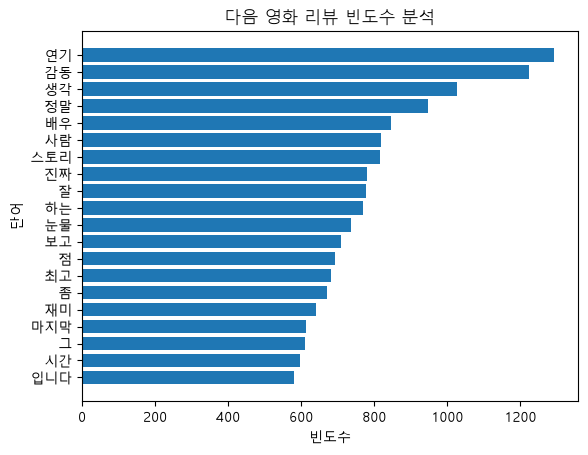

In [62]:
# 시각화 - 수평 막대 그래프
import matplotlib.pyplot as plt

# (1) 데이터 준비
x = [word for word, count in count_list]#튜플에서 앞에있는것 
y = [count for word, count in count_list]#튜플에서 뒤에있는것 

# k=[], y =[]
# for.word, count .in.count_list:
#   x.append(word)
#   y. append (count)

# (2) 그래프 생성
plt.barh(x[::-1], y[::-1])

# (3) 정보추가
plt.title("다음 영화 리뷰 빈도수 분석")
plt.xlabel('빈도수')
plt.ylabel('단어')
# (4) 출력
#plt.show()
plt.savefig('result\daum_movie_review_graph.jpg')

# 숙제

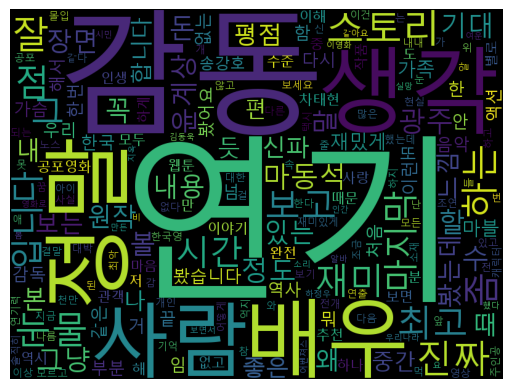

In [63]:
# 다음 영화 리뷰 wordcloud 생성
from wordcloud import WordCloud
font_path = 'C:/Windows/Fonts/malgun.ttf'

wc = WordCloud(
    font_path=font_path,
    width=800,
    height=600
)

wc = wc.generate_from_frequencies(counter)
plt.imshow(wc)
plt.axis('off')
plt.show()

In [64]:
wc.to_file("result/daum_movie_review_wordcloud.jpg")

In [39]:
from matplotlib import font_manager, rc
font_path = "c:/Windows/Fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

In [40]:
# 대한민국 헌법 wordcloud 생성하기
from konlpy. corpus import kolaw
input_filename = 'constitution.txt'
const_doc = kolaw.open(input_filename).read()
len(const_doc), type(const_doc)

(18884, str)

In [41]:
const_doc[:100]

'대한민국헌법\n\n유구한 역사와 전통에 빛나는 우리 대한국민은 3·1운동으로 건립된 대한민국임시정부의 법통과 불의에 항거한 4·19민주이념을 계승하고, 조국의 민주개혁과 평화적 통일의'

In [42]:
# wordcloud 설치
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [43]:
from wordcloud import WordCloud
font_path = 'C:/Windows/Fonts/malgun.ttf'
# Wordcloud 클래스의 객체 생성
wc= WordCloud(
    font_path
)

In [44]:
# 워드클라우드 생성 from 텍스트
Wc = wc. generate(const_doc)

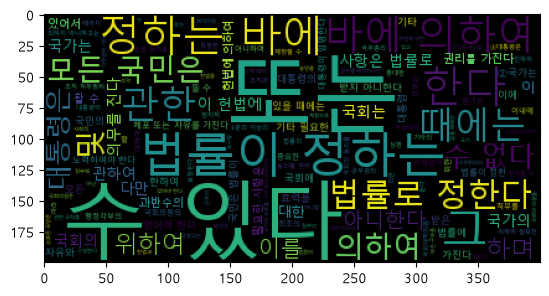

In [45]:
# matplotlib의 pyplot과 연동
import matplotlib. pyplot as plt
plt.imshow(wc)

In [46]:
#헌법 -> 전처리 -> 빈도수 객체 (Counter)

#전처리>토큰화>정제>정규화
from konlpy.tag import Okt
tagger = Okt().pos

tokens = tagger(const_doc)
tokens = tagger(const_doc)
tokens [: 10]

[('대한민국', 'Noun'),
 ('헌법', 'Noun'),
 ('\n\n', 'Foreign'),
 ('유구', 'Noun'),
 ('한', 'Josa'),
 ('역사', 'Noun'),
 ('와', 'Josa'),
 ('전통', 'Noun'),
 ('에', 'Josa'),
 ('빛나는', 'Verb')]

In [47]:
# 불용어 제거 : 원하는 품사 정의, 삭제할 단어 사전 정의
my_tags = ['Noun' ]
my_stopwords = ["법률","제","정"]

result_list = [word for word, tag in tokens if tag in my_tags and word not in my_stopwords]

In [48]:
# 빈도수 계산 : Counter 클래스
from collections import Counter
counter = Counter(result_list)

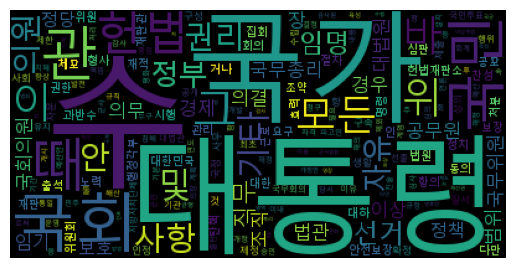

In [49]:
# 워드클라우드 적용
wc = wc. generate_from_frequencies(counter)
plt.imshow(wc)
plt.axis('off')
plt.show()

In [50]:
# wordcloud 이미지를 파일로 저장
wc.to_file("result/const_doc_wordcloud.jpg")